<a href="https://colab.research.google.com/github/DSlayer28/pytorch_tutorials/blob/main/Tabular_Data_Classification_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download(
    "mssmartypants/rice-type-classification"
)

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'rice-type-classification' dataset.
Dataset downloaded to: /kaggle/input/rice-type-classification


In [17]:
import torch # Torch main framework
import torch.nn as nn # Used for getting the NN Layers
from torch.optim import Adam # Adam Optimizer
from torch.utils.data import Dataset, DataLoader # Dataset class and DataLoader for creatning the objects
from torchsummary import summary # Visualize the model layers and number of parameters
from sklearn.model_selection import train_test_split # Split the dataset (train, validation, test)
from sklearn.metrics import accuracy_score # Calculate the testing Accuracy
import matplotlib.pyplot as plt # Plotting the training progress at the end
import pandas as pd # Data reading and preprocessing
import numpy as np # Mathematical operations

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [18]:
import os
import glob
import pandas as pd

# Find the CSV inside the downloaded dataset directory
csv_files = glob.glob(
    os.path.join(path, "**", "riceClassification.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError(
        f"riceClassification.csv was not found inside: {path}"
    )

data_df = pd.read_csv(csv_files[0])

data_df.dropna(inplace=True)
data_df.drop("id", axis=1, inplace=True)

print("Output possibilities:", data_df["Class"].unique())
print("Data shape:", data_df.shape)

data_df.head()

Output possibilities: [1 0]
Data shape: (18185, 11)


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [19]:
print(data_df["Class"].unique())
print(data_df["Class"].value_counts())

[1 0]
Class
1    9985
0    8200
Name: count, dtype: int64


In [20]:
copy_df = data_df.copy()

for column in copy_df.columns:
  copy_df[column] = copy_df[column]/copy_df[column].abs().max()
copy_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,0.444368,0.503404,0.775435,0.744658,0.424873,0.666610,0.741661,0.537029,0.844997,0.368316,1.0
1,0.281293,0.407681,0.622653,0.750489,0.273892,0.530370,0.804230,0.409661,0.919215,0.371471,1.0
2,0.298531,0.416421,0.630442,0.756341,0.284520,0.546380,0.856278,0.412994,0.959862,0.374747,1.0
3,0.300979,0.420463,0.629049,0.764024,0.286791,0.548616,0.883772,0.414262,0.961818,0.379222,1.0
4,0.361704,0.464626,0.682901,0.775033,0.345385,0.601418,0.867808,0.452954,0.966836,0.386007,1.0


In [21]:
X = data_df.drop(columns=["Class"]).to_numpy(dtype=np.float32)
Y = data_df["Class"].to_numpy(dtype=np.float32)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Calculate scaling factors using only the training data
scale = np.max(np.abs(X_train), axis=0)
scale[scale == 0] = 1.0

# Apply the same factors to all three sets
X_train = X_train / scale
X_val = X_val / scale
X_test = X_test / scale

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (12729, 10)
Validation: (2728, 10)
Testing: (2728, 10)


In [22]:
class RiceDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.Y[index]


training_data = RiceDataset(X_train, y_train)
validation_data = RiceDataset(X_val, y_val)
testing_data = RiceDataset(X_test, y_test)

In [23]:
BATCH_SIZE = 32
EPOCHS = 10
HIDDEN_NEURONS = 10
LR = 1e-3

train_dataloader = DataLoader(
    training_data, batch_size=BATCH_SIZE, shuffle=True
)

validation_dataloader = DataLoader(
    validation_data, batch_size=BATCH_SIZE, shuffle=False
)

testing_dataloader = DataLoader(
    testing_data, batch_size=BATCH_SIZE, shuffle=False
)

In [24]:
class MyModel(nn.Module):
    def __init__(self):

        super(MyModel, self).__init__()

        self.input_layer = nn.Linear(X.shape[1], HIDDEN_NEURONS)
        self.linear = nn.Linear(HIDDEN_NEURONS, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.input_layer(x)
        x = self.linear(x)
        x = self.sigmoid(x)
        return x

In [25]:
model = MyModel().to(device)
summary(model, (X.shape[1],))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 10]             110
            Linear-2                    [-1, 1]              11
           Sigmoid-3                    [-1, 1]               0
Total params: 121
Trainable params: 121
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [26]:
criterion = nn.BCELoss()
optimizer = Adam(model.parameters(), lr= LR)

In [27]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []

for epoch in range(EPOCHS):
    total_acc_train = 0
    total_loss_train = 0
    total_acc_val = 0
    total_loss_val = 0
    ## Training and Validation
    for data in train_dataloader:

        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        prediction = model(inputs).squeeze(1)

        batch_loss = criterion(prediction, labels)

        total_loss_train += batch_loss.item()

        acc = ((prediction).round() == labels).sum().item()

        total_acc_train += acc

        batch_loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    ## Validation
    with torch.no_grad():
      for data in validation_dataloader:
          inputs, labels = data

          inputs = inputs.to(device)
          labels = labels.to(device)

          prediction = model(inputs).squeeze(1)
          batch_loss = criterion(prediction, labels)

          total_loss_val += batch_loss.item()

          acc = (prediction.round() == labels).sum().item()
          total_acc_val += acc

    total_loss_train_plot.append(round(total_loss_train/1000, 4))
    total_loss_validation_plot.append(round(total_loss_val/1000, 4))
    total_acc_train_plot.append(round(total_acc_train/(training_data.__len__())*100, 4))
    total_acc_validation_plot.append(round(total_acc_val/(validation_data.__len__())*100, 4))

    print(f'''Epoch no. {epoch + 1} Train Loss: {total_loss_train/1000:.4f} Train Accuracy: {(total_acc_train/(training_data.__len__())*100):.4f} Validation Loss: {total_loss_val/1000:.4f} Validation Accuracy: {(total_acc_val/(validation_data.__len__())*100):.4f}''')
    print("="*50)

Epoch no. 1 Train Loss: 0.2392 Train Accuracy: 82.3788 Validation Loss: 0.0407 Validation Accuracy: 97.8006
Epoch no. 2 Train Loss: 0.1263 Train Accuracy: 97.3054 Validation Loss: 0.0172 Validation Accuracy: 98.1672
Epoch no. 3 Train Loss: 0.0583 Train Accuracy: 98.0281 Validation Loss: 0.0094 Validation Accuracy: 98.4238
Epoch no. 4 Train Loss: 0.0367 Train Accuracy: 98.3895 Validation Loss: 0.0066 Validation Accuracy: 98.6804
Epoch no. 5 Train Loss: 0.0280 Train Accuracy: 98.3659 Validation Loss: 0.0054 Validation Accuracy: 98.7903
Epoch no. 6 Train Loss: 0.0239 Train Accuracy: 98.5073 Validation Loss: 0.0049 Validation Accuracy: 98.7537
Epoch no. 7 Train Loss: 0.0214 Train Accuracy: 98.4759 Validation Loss: 0.0043 Validation Accuracy: 98.8636
Epoch no. 8 Train Loss: 0.0200 Train Accuracy: 98.5466 Validation Loss: 0.0040 Validation Accuracy: 98.8270
Epoch no. 9 Train Loss: 0.0189 Train Accuracy: 98.4916 Validation Loss: 0.0038 Validation Accuracy: 98.8636
Epoch no. 10 Train Loss: 0.0

In [28]:
with torch.no_grad():
    model.eval()

    total_loss_test = 0
    total_acc_test = 0

    for data in testing_dataloader:
        inputs, labels = data

        inputs = inputs.to(device)  # Added
        labels = labels.to(device)  # Added

        prediction = model(inputs).squeeze(1)

        batch_loss_test = criterion(prediction, labels)
        total_loss_test += batch_loss_test.item()

        acc = (prediction.round() == labels).sum().item()
        total_acc_test += acc

print(f"Accuracy Score is: {round((total_acc_test / len(testing_data)) * 100, 2)}%")

Accuracy Score is: 98.94%


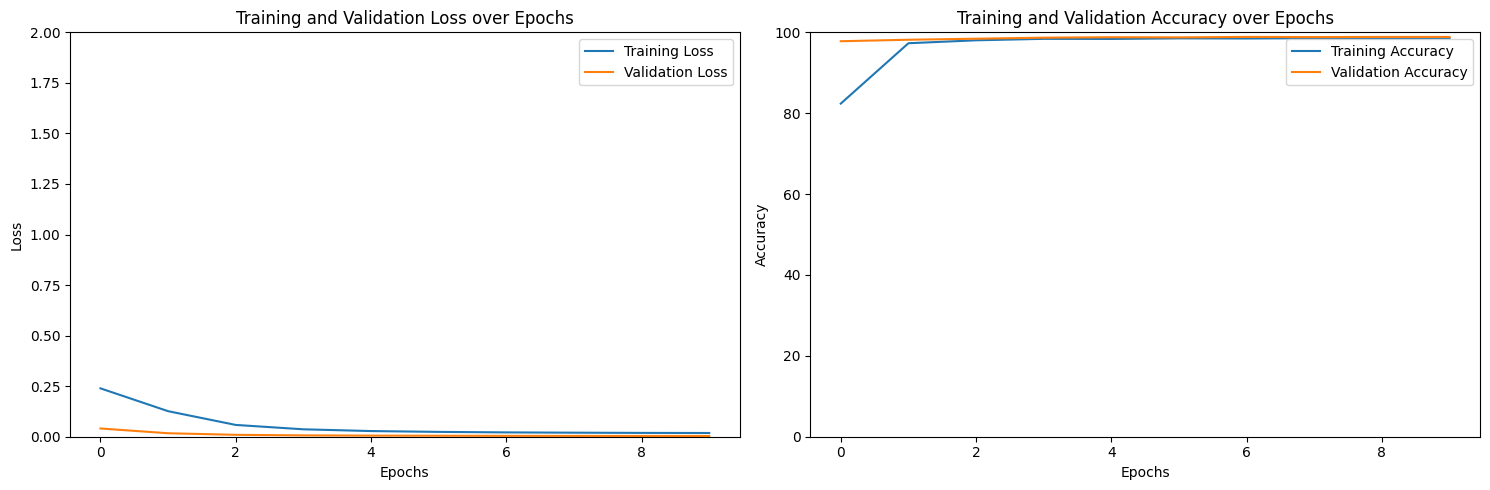

In [29]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].plot(total_loss_validation_plot, label='Validation Loss')
axs[0].set_title('Training and Validation Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].set_ylim([0, 2])
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].plot(total_acc_validation_plot, label='Validation Accuracy')
axs[1].set_title('Training and Validation Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].set_ylim([0, 100])
axs[1].legend()

plt.tight_layout()

plt.show()

In [30]:
area = float(input("Area: ")) / scale[0]
MajorAxisLength = float(input("Major Axis Length: ")) / scale[1]
MinorAxisLength = float(input("Minor Axis Length: ")) / scale[2]
Eccentricity = float(input("Eccentricity: ")) / scale[3]
ConvexArea = float(input("Convex Area: ")) / scale[4]
EquivDiameter = float(input("Equivalent Diameter: ")) / scale[5]
Extent = float(input("Extent: ")) / scale[6]
Perimeter = float(input("Perimeter: ")) / scale[7]
Roundness = float(input("Roundness: ")) / scale[8]
AspectRation = float(input("Aspect Ratio: ")) / scale[9]

my_inputs = [
    area,
    MajorAxisLength,
    MinorAxisLength,
    Eccentricity,
    ConvexArea,
    EquivDiameter,
    Extent,
    Perimeter,
    Roundness,
    AspectRation
]

print("=" * 20)

model_inputs = torch.tensor(
    [my_inputs], dtype=torch.float32
).to(device)

model.eval()

with torch.no_grad():
    prediction = model(model_inputs)

print("Prediction probability:", prediction.item())
print("Class is:", int(prediction.item() >= 0.5))

Area: 7665
Major Axis Length: 146
Minor Axis Length: 56
Eccentricity: 0.9099856545
Convex Area: 6558.986465611216
Equivalent Diameter: 90.5
Extent: 0.85
Perimeter: 328.5644551245
Roundness: 0.85651375464
Aspect Ratio: 2.511156
Prediction probability: 0.26885247230529785
Class is: 0
